In [ ]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msno

import warnings
warnings.filterwarnings('ignore')

sns.set()
plt.style.use('ggplot')

In [ ]:
df = pd.read_csv("breast_cancer_prediction.csv")

print("Shape:", df.shape)

df.head()

Shape: (10000, 23)


,Patient_ID,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,...,Mammogram_Result,Biopsy_Result,Cancer_Stage,Cancer,Blood_Pressure,Cholesterol,Diabetes,Exercise_Days_Per_Week,Breastfeeding_History,Annual_Income_USD
0,100001,71,Female,27.2,Yes,Yes,Yes,High,No,Post,...,Suspicious,Malignant,Stage II,1,141,167,No,7,No,101316
1,100002,34,Male,26.0,No,No,No,High,No,Post,...,Normal,Benign,No Cancer,0,104,229,Yes,7,Yes,30023
2,100003,80,Female,20.7,No,No,No,High,No,Pre,...,Suspicious,Benign,No Cancer,0,161,275,No,1,Yes,34819
3,100004,40,Female,26.8,Yes,Yes,No,Moderate,No,Post,...,Normal,Benign,No Cancer,0,150,180,No,7,Yes,68025
4,100005,43,Female,28.6,Yes,Yes,No,Moderate,No,Post,...,Normal,Benign,No Cancer,0,110,266,No,0,Yes,90919


In [ ]:
df.Biopsy_Result.unique()

array(['Malignant', 'Benign'], dtype=object)

In [ ]:
# Supervised-> target
# Unsupervised
df.describe()

,Patient_ID,Age,BMI,Tumor_Size_cm,Cancer,Blood_Pressure,Cholesterol,Exercise_Days_Per_Week,Annual_Income_USD
count,10000.00000,10000.000000,9700.000000,9700.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,105000.50000,52.033800,27.051227,2.630334,0.193300,134.811100,214.071500,3.535200,82337.305000
std,2886.89568,18.789517,4.494501,1.589789,0.394906,26.174742,49.242034,2.282385,39102.629984
min,100001.00000,20.000000,11.100000,0.000000,0.000000,90.000000,130.000000,0.000000,15002.000000
25%,102500.75000,36.000000,24.000000,1.370000,0.000000,112.000000,172.000000,2.000000,48145.750000
50%,105000.50000,52.000000,27.000000,2.510000,0.000000,135.000000,213.000000,4.000000,81813.500000
75%,107500.25000,68.000000,30.100000,3.720000,0.000000,157.000000,257.000000,6.000000,116217.500000
max,110000.00000,84.000000,44.100000,9.880000,1.000000,180.000000,300.000000,7.000000,149996.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Patient_ID              10000 non-null  int64  
 1   Age                     10000 non-null  int64  
 2   Gender                  10000 non-null  object 
 3   BMI                     9700 non-null   float64
 4   Family_History          10000 non-null  object 
 5   Smoking                 10000 non-null  object 
 6   Alcohol_Consumption     9700 non-null   object 
 7   Physical_Activity       9700 non-null   object 
 8   Hormone_Therapy         9700 non-null   object 
 9   Menopause_Status        10000 non-null  object 
 10  Genetic_Mutation        10000 non-null  object 
 11  Tumor_Size_cm           9700 non-null   float64
 12  Lymph_Node_Involvement  10000 non-null  object 
 13  Mammogram_Result        10000 non-null  object 
 14  Biopsy_Result           10000 non-null 

In [ ]:
# missing value
df.isnull().sum()

,0
Patient_ID,0
Age,0
Gender,0
BMI,300
Family_History,0
Smoking,0
Alcohol_Consumption,300
Physical_Activity,300
Hormone_Therapy,300
Menopause_Status,0


In [ ]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns

categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print("Numerical Columns:")
print(numerical_columns.tolist())

print("\nCategorical Columns:")
print(categorical_columns.tolist())

Numerical Columns:
['Patient_ID', 'Age', 'BMI', 'Tumor_Size_cm', 'Cancer', 'Blood_Pressure', 'Cholesterol', 'Exercise_Days_Per_Week', 'Annual_Income_USD']

Categorical Columns:
['Gender', 'Family_History', 'Smoking', 'Alcohol_Consumption', 'Physical_Activity', 'Hormone_Therapy', 'Menopause_Status', 'Genetic_Mutation', 'Lymph_Node_Involvement', 'Mammogram_Result', 'Biopsy_Result', 'Cancer_Stage', 'Diabetes', 'Breastfeeding_History']


In [ ]:
for column in numerical_columns:
    df[column] = df[column].fillna(
        df[column].median()
    )

for column in categorical_columns:
    df[column] = df[column].fillna(
        df[column].mode()[0]
    )

In [ ]:
df.isnull().sum()

,0
Patient_ID,0
Age,0
Gender,0
BMI,0
Family_History,0
Smoking,0
Alcohol_Consumption,0
Physical_Activity,0
Hormone_Therapy,0
Menopause_Status,0


<Axes: >

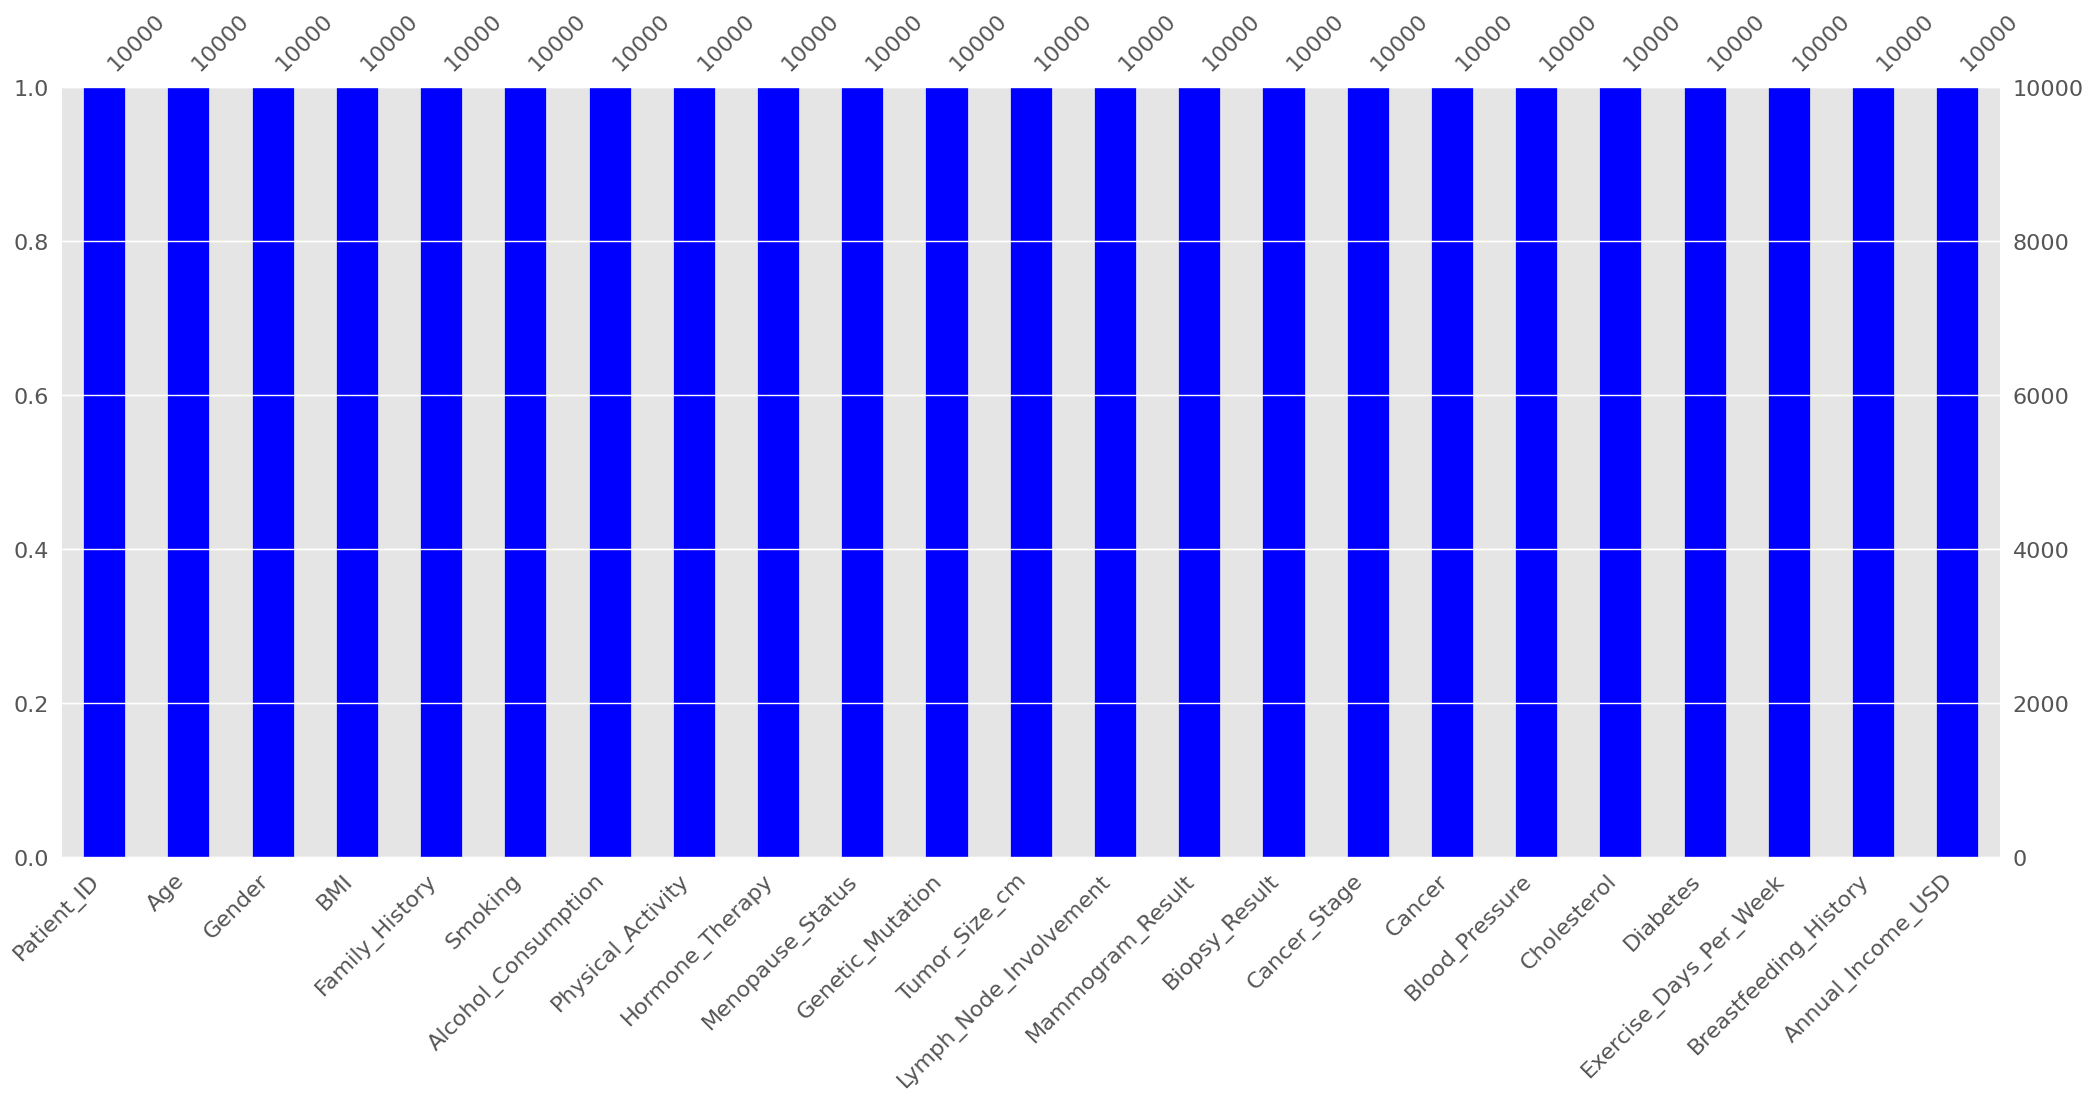

In [ ]:
msno.bar(df, color="blue")

In [ ]:
df['Biopsy_Result'] = df['Biopsy_Result'].map({
    'Malignant':1,
    'Benign':0
})

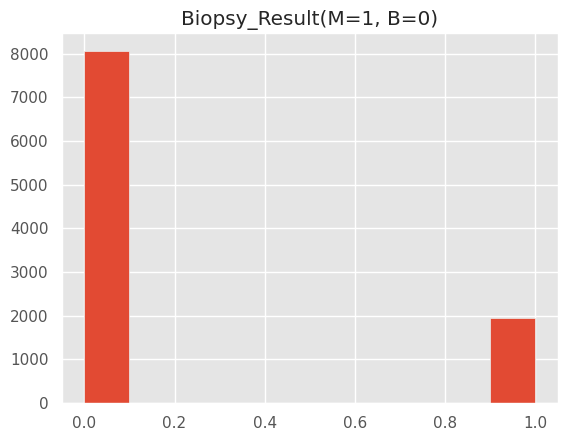

In [ ]:
plt.hist(df['Biopsy_Result'])
plt.title('Biopsy_Result(M=1, B=0)')
plt.show()

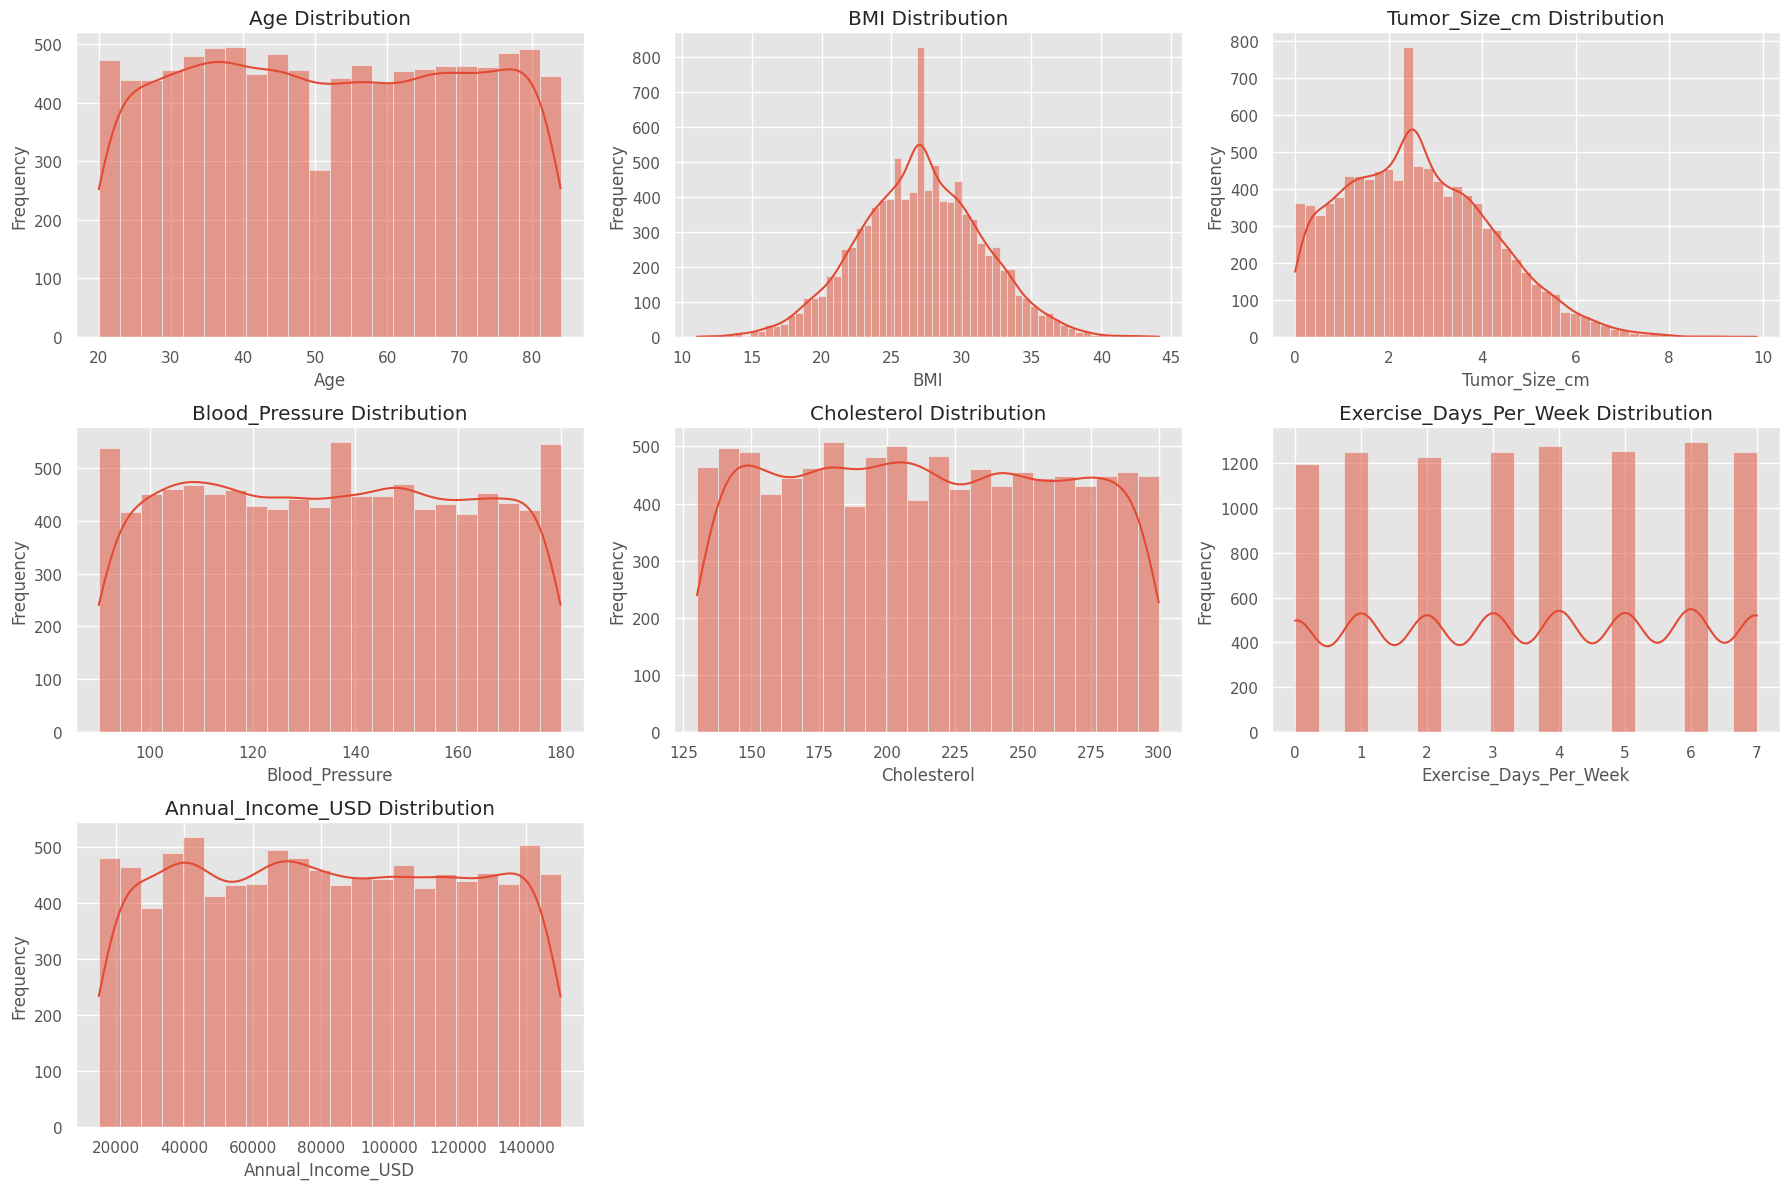

In [ ]:
# Numerical columns
numerical_columns = [
    'Age',
    'BMI',
    'Tumor_Size_cm',
    'Blood_Pressure',
    'Cholesterol',
    'Exercise_Days_Per_Week',
    'Annual_Income_USD'
]

# Create subplots
n_cols = 3
n_rows = int(np.ceil(len(numerical_columns) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 12)
)

axes = axes.flatten()

# Plot each numerical column
for i, column in enumerate(numerical_columns):

    sns.histplot(
        data=df,
        x=column,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f'{column} Distribution')
    axes[i].set_xlabel(column)
    axes[i].set_ylabel('Frequency')

# Remove unused subplots
for i in range(len(numerical_columns), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

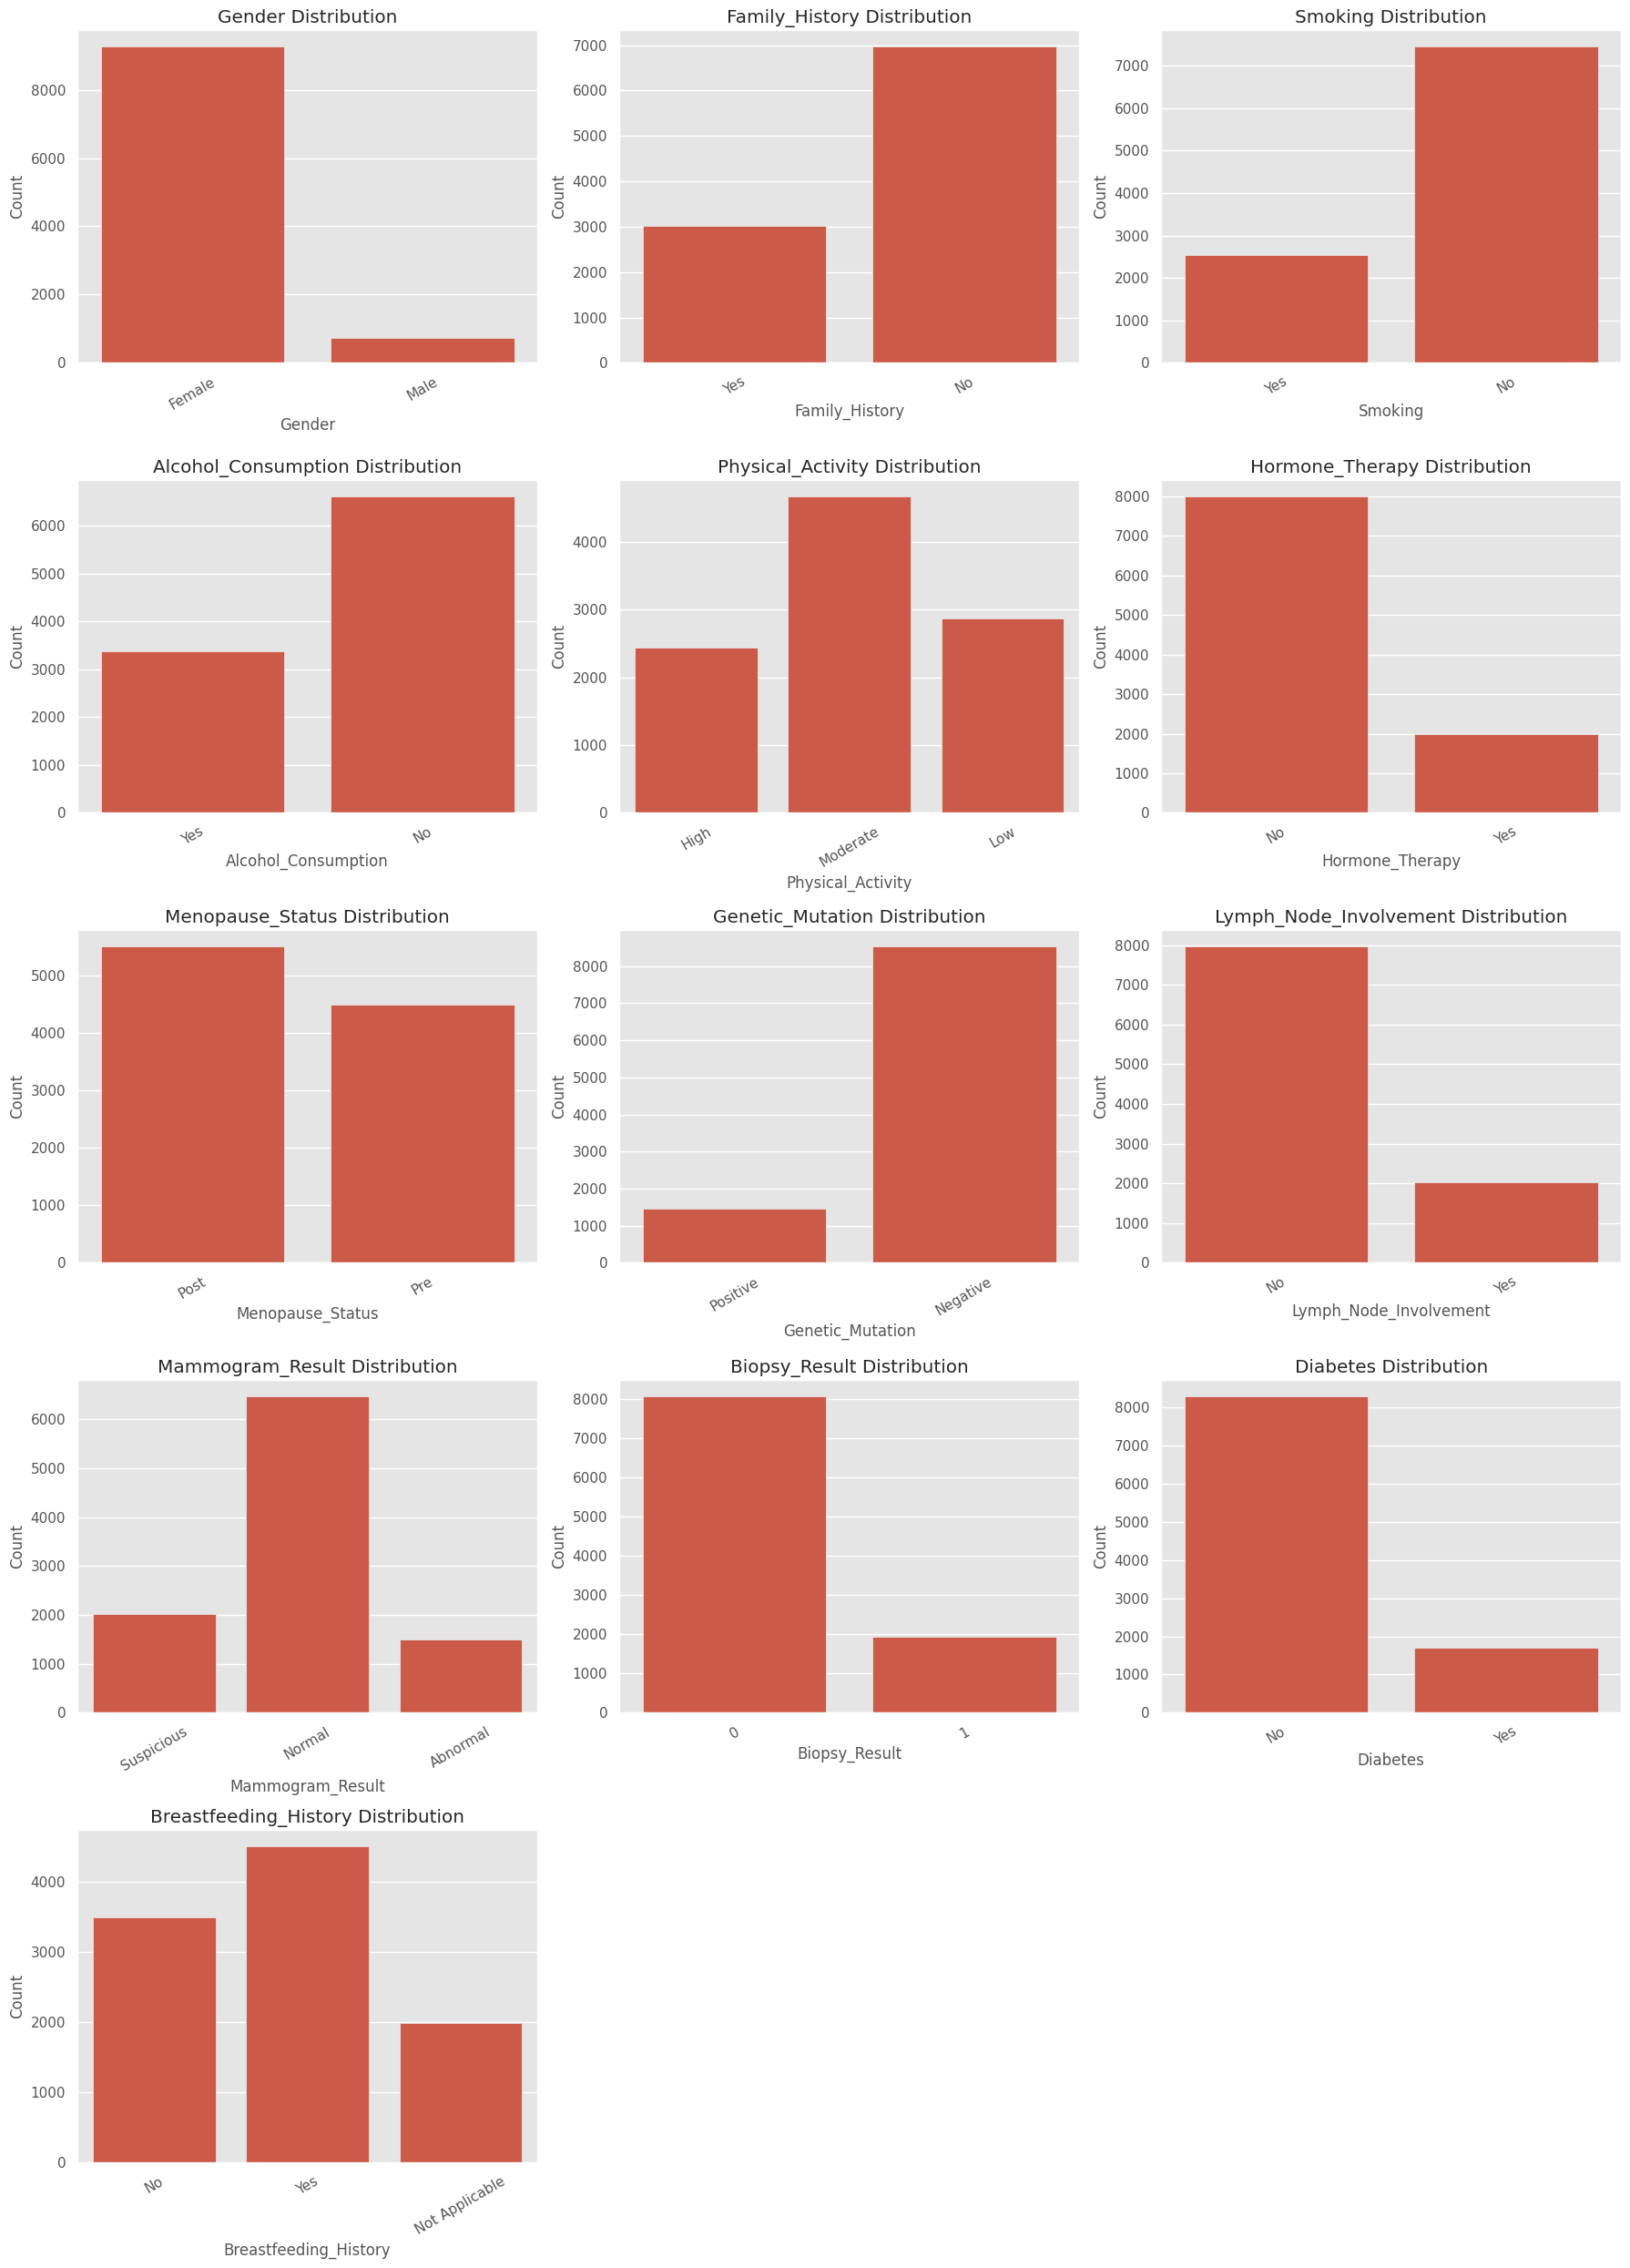

In [ ]:
# Categorical columns
categorical_columns = [
    'Gender',
    'Family_History',
    'Smoking',
    'Alcohol_Consumption',
    'Physical_Activity',
    'Hormone_Therapy',
    'Menopause_Status',
    'Genetic_Mutation',
    'Lymph_Node_Involvement',
    'Mammogram_Result',
    'Biopsy_Result',
    'Diabetes',
    'Breastfeeding_History'
]

# Create subplots
n_cols = 3
n_rows = int(np.ceil(len(categorical_columns) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 25)
)

axes = axes.flatten()

# Plot each categorical column
for i, column in enumerate(categorical_columns):

    sns.countplot(
        data=df,
        x=column,
        ax=axes[i]
    )

    axes[i].set_title(f'{column} Distribution')
    axes[i].set_xlabel(column)
    axes[i].set_ylabel('Count')

    # Rotate labels for readability
    axes[i].tick_params(
        axis='x',
        rotation=30
    )

# Remove unused subplots
for i in range(len(categorical_columns), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

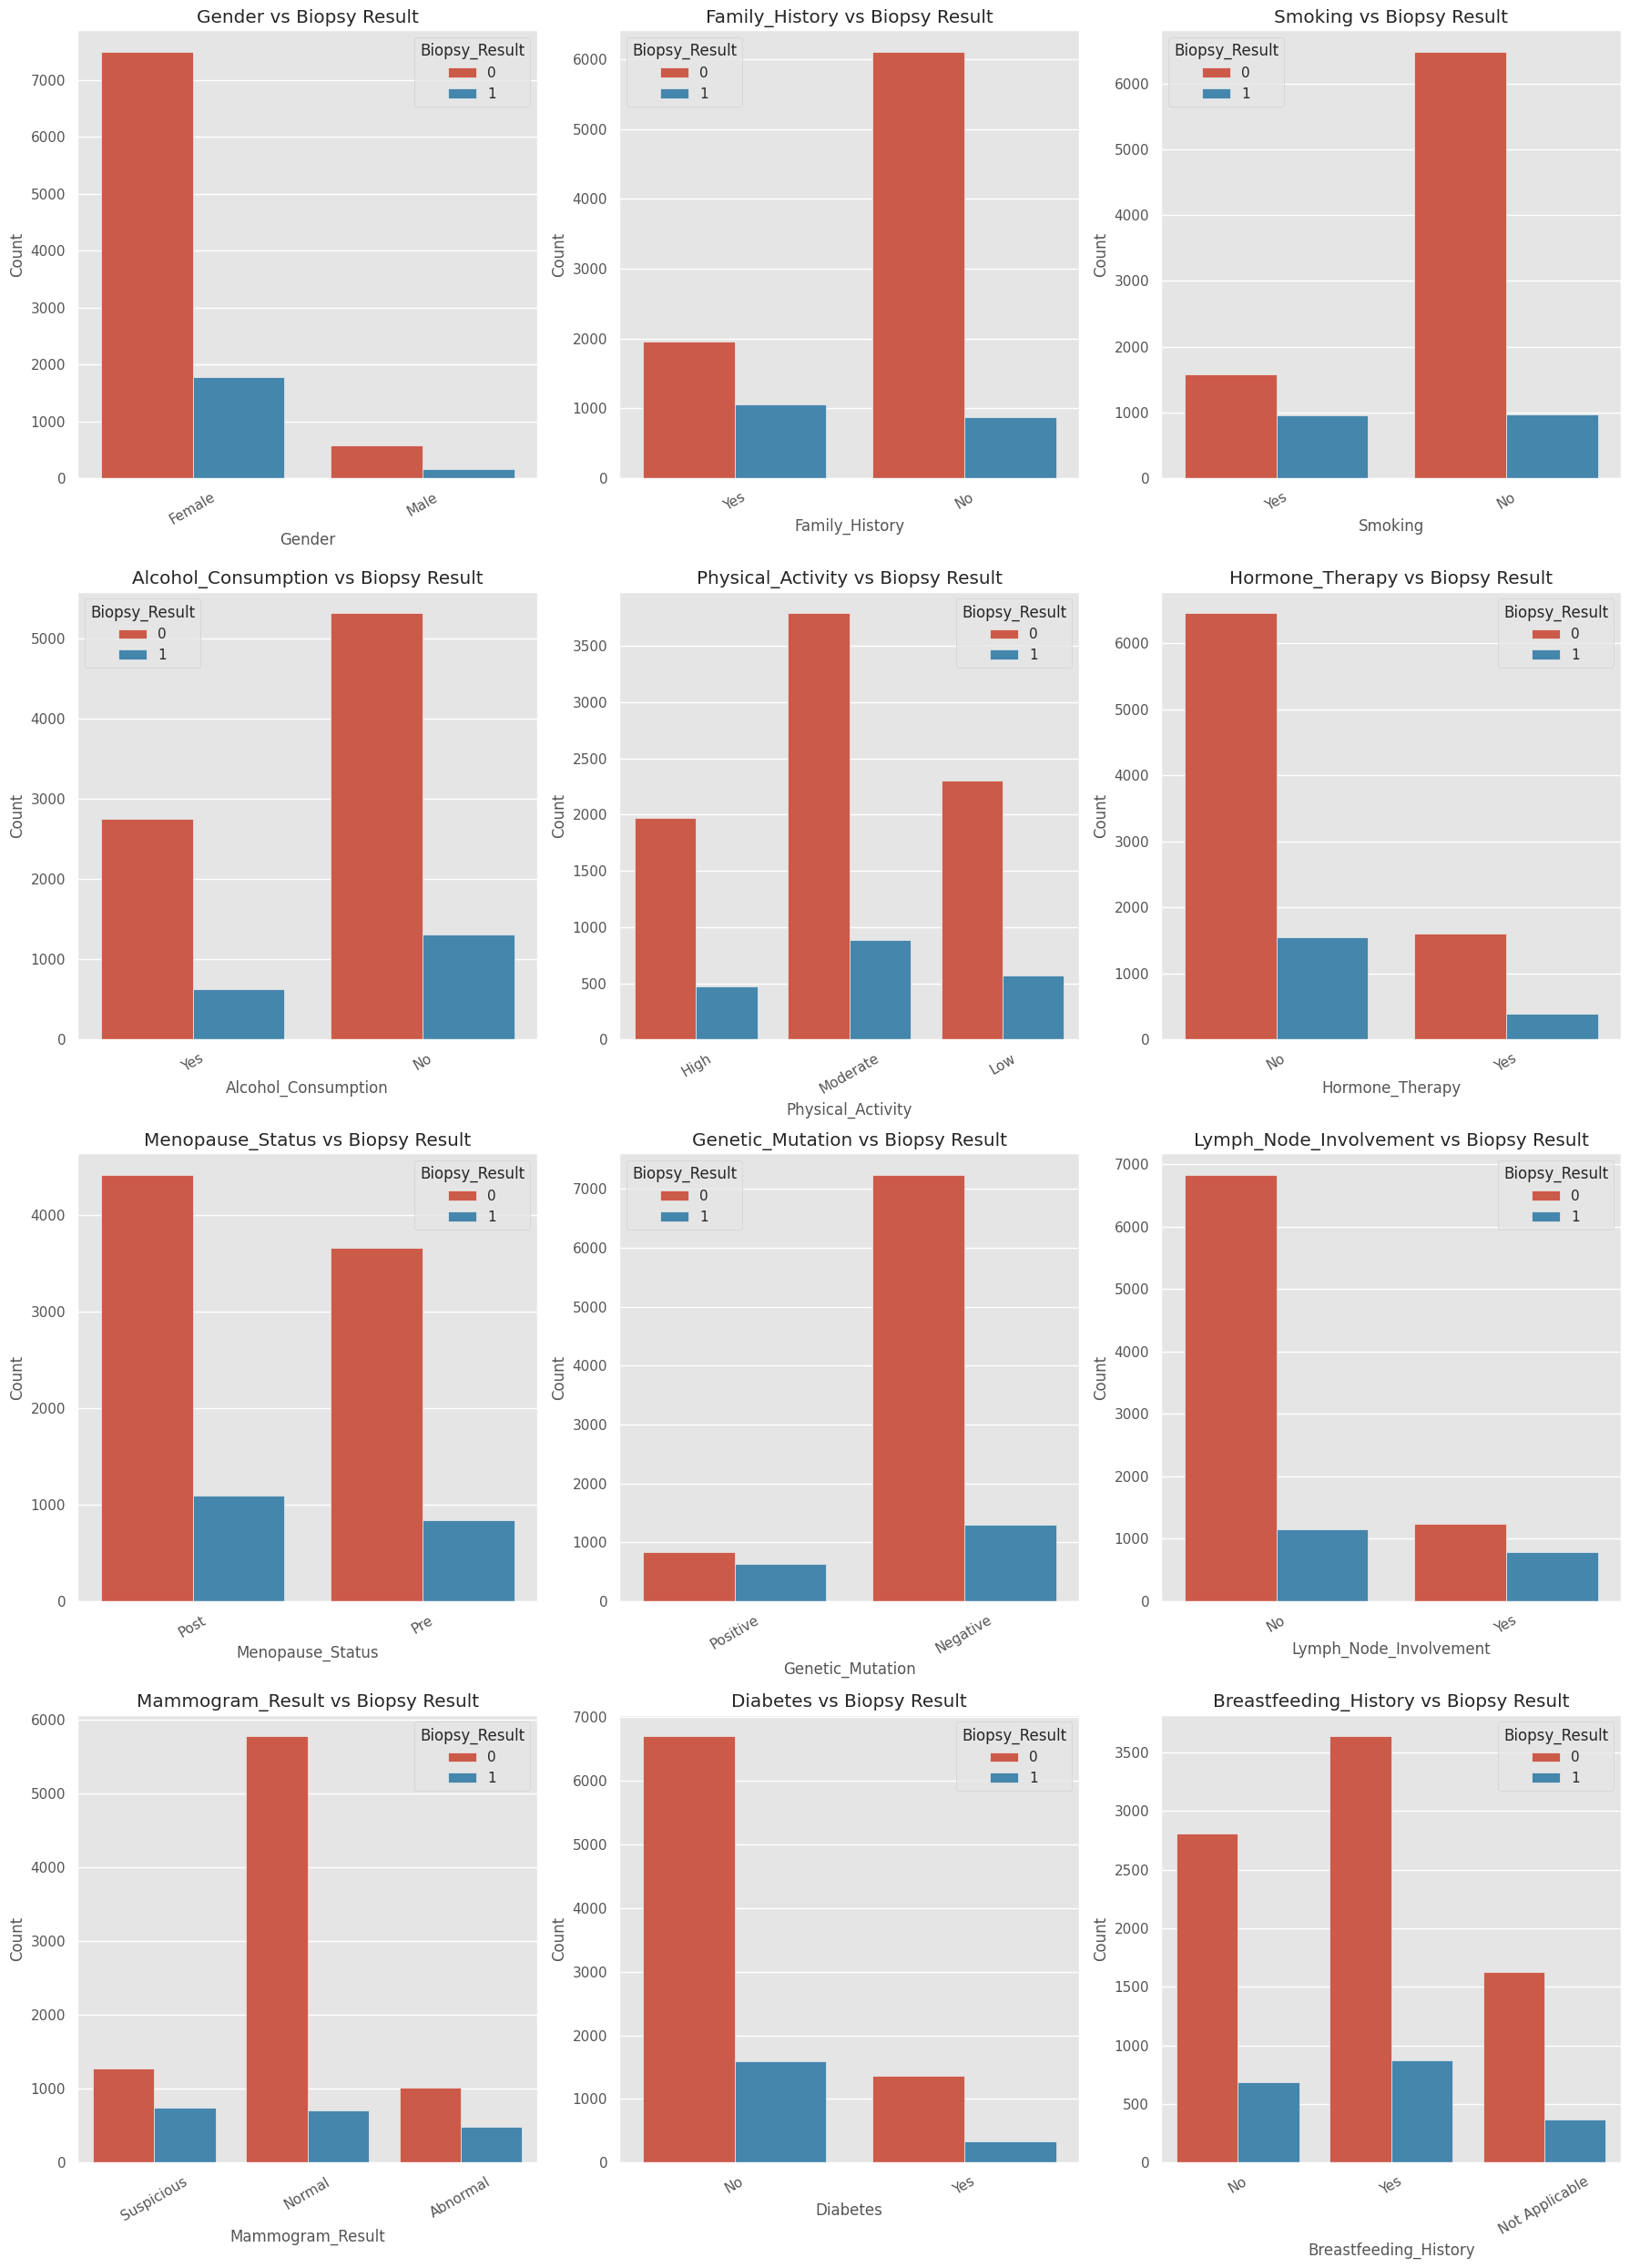

In [ ]:
categorical_features = [
    'Gender',
    'Family_History',
    'Smoking',
    'Alcohol_Consumption',
    'Physical_Activity',
    'Hormone_Therapy',
    'Menopause_Status',
    'Genetic_Mutation',
    'Lymph_Node_Involvement',
    'Mammogram_Result',
    'Diabetes',
    'Breastfeeding_History'
]

n_cols = 3
n_rows = int(np.ceil(len(categorical_features) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 25)
)

axes = axes.flatten()

for i, column in enumerate(categorical_features):

    sns.countplot(
        data=df,
        x=column,
        hue='Biopsy_Result',
        ax=axes[i]
    )

    axes[i].set_title(
        f'{column} vs Biopsy Result'
    )

    axes[i].set_xlabel(column)
    axes[i].set_ylabel('Count')

    axes[i].tick_params(
        axis='x',
        rotation=30
    )

for i in range(len(categorical_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

In [ ]:
df.drop('Cancer', axis=1, inplace=True)

In [ ]:
df.drop('Patient_ID', axis=1, inplace=True)

In [ ]:
# Select only numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Calculate correlation
correlation = numeric_df.corr()

# Display correlation
correlation

,Age,BMI,Tumor_Size_cm,Biopsy_Result,Blood_Pressure,Cholesterol,Exercise_Days_Per_Week,Annual_Income_USD
Age,1.000000,0.011186,-0.006141,0.220109,-0.010177,0.001655,0.007778,0.006729
BMI,0.011186,1.000000,0.016716,0.206862,0.005044,-0.018730,-0.007835,0.002294
Tumor_Size_cm,-0.006141,0.016716,1.000000,0.215262,-0.016907,0.008319,0.003314,-0.003129
Biopsy_Result,0.220109,0.206862,0.215262,1.000000,-0.003849,-0.003437,0.010148,0.013801
Blood_Pressure,-0.010177,0.005044,-0.016907,-0.003849,1.000000,-0.007997,-0.008950,-0.008314
Cholesterol,0.001655,-0.018730,0.008319,-0.003437,-0.007997,1.000000,-0.001388,0.005015
Exercise_Days_Per_Week,0.007778,-0.007835,0.003314,0.010148,-0.008950,-0.001388,1.000000,-0.018933
Annual_Income_USD,0.006729,0.002294,-0.003129,0.013801,-0.008314,0.005015,-0.018933,1.000000


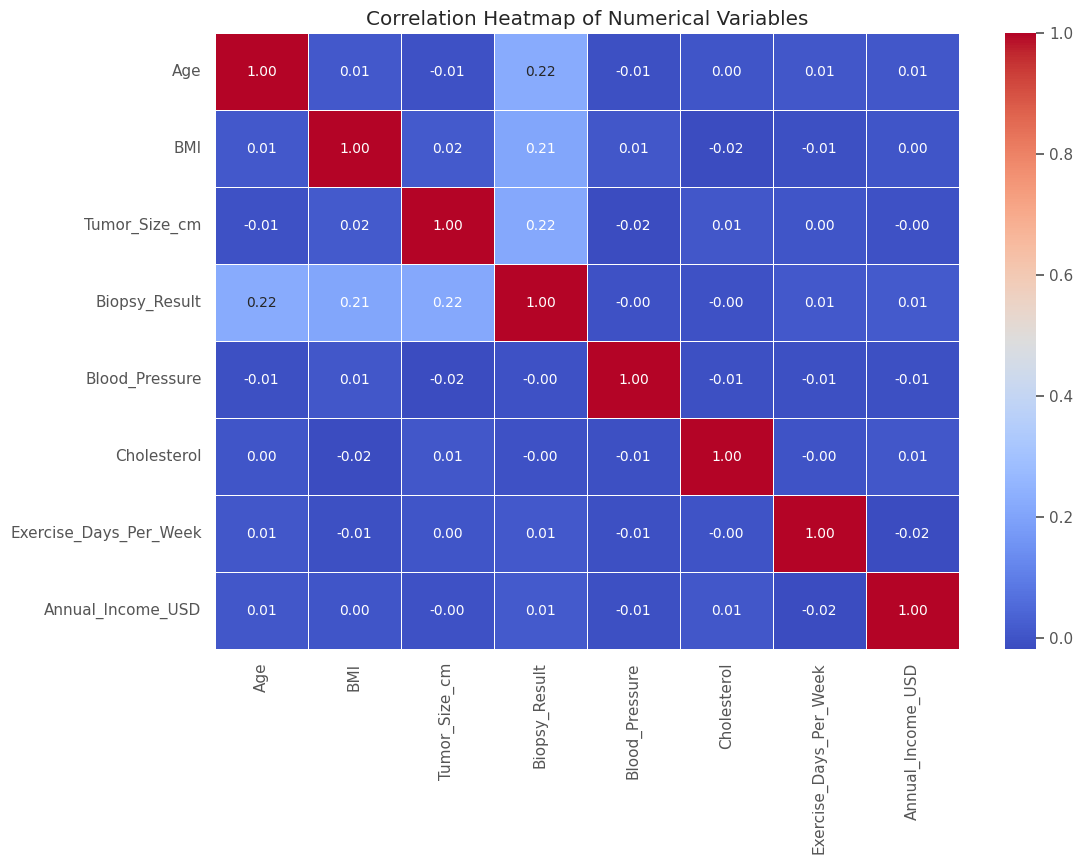

In [ ]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

correlation['Biopsy_Result'].sort_values(
    ascending=False
)

,Biopsy_Result
Biopsy_Result,1.000000
Age,0.220109
Tumor_Size_cm,0.215262
BMI,0.206862
Annual_Income_USD,0.013801
Exercise_Days_Per_Week,0.010148
Cholesterol,-0.003437
Blood_Pressure,-0.003849


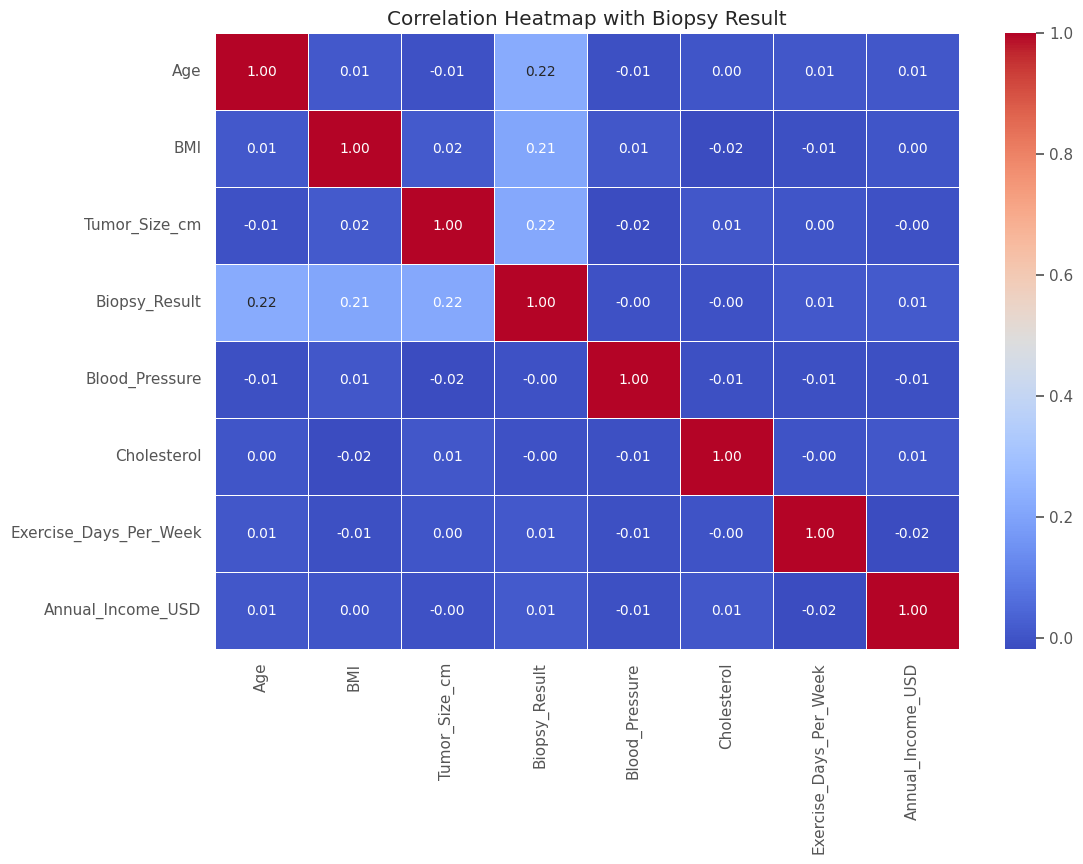

In [ ]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5
)

plt.title("Correlation Heatmap with Biopsy Result")
plt.show()

In [ ]:
# Convert all categorical columns to numerical
df = pd.get_dummies(df, drop_first=True)

In [ ]:
cols_to_drop = [
    'Mammogram_Result_Normal',
    'Mammogram_Result_Suspicious',
    'Cancer_Stage_Stage I',
    'Cancer_Stage_Stage II',
    'Cancer_Stage_Stage III',
    'Cancer_Stage_Stage IV'
]

df.drop(
    columns=[c for c in cols_to_drop if c in df.columns],
    inplace=True
)

In [ ]:
corr_matrix = correlation.abs()

mask = np.triu(np.ones_like(corr_matrix,dtype=bool))

tri_df = corr_matrix.mask(mask)

to_drop = [
    c for c in tri_df.columns
    if any(tri_df[c] > 0.92)
]

print("Columns Removed:")
print(to_drop)

Columns Removed:
[]


In [ ]:
df = df.drop(to_drop, axis=1)

print(df.shape)

(10000, 21)


In [ ]:
X = df.drop('Biopsy_Result', axis=1)
y = df['Biopsy_Result']

## Modeling Pipeline — Rebuilt for NiT Use Case ObjectivesMandatory models: **Logistic Regression** and **Random Forest**.This section fixes issues found in the original pipeline and directly targets the stated objectives:- Single, clean train/test split (previous version silently re-split and lost feature scaling for every model trained after it — this version doesn't).- Class imbalance handled **two ways** so you can compare: `class_weight='balanced'` and **SMOTE** oversampling (both requested in the use case).- Hyperparameter tuning via `GridSearchCV` for both mandatory models.- Evaluation prioritizes **recall on Malignant** (missed cancer cases are the costly error), alongside accuracy/precision/F1/ROC-AUC.- Feature importance for both models (interpretability requirement).- SHAP explainability retained for the tree model.- Final model pickled for deployment.> Note: `imbalanced-learn` is required for SMOTE. In Colab run: `!pip install imbalanced-learn` if not already installed.

In [ ]:
!pip install -q imbalanced-learn

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFoldfrom sklearn.preprocessing import StandardScalerfrom sklearn.linear_model import LogisticRegressionfrom sklearn.ensemble import RandomForestClassifierfrom sklearn.metrics import (    accuracy_score, precision_score, recall_score, f1_score,    roc_auc_score, confusion_matrix, classification_report, roc_curve)from imblearn.over_sampling import SMOTEimport pandas as pdimport numpy as npimport matplotlib.pyplot as pltimport seaborn as sns

### 1. Single train/test split (stratified, no re-splitting later)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(    X, y,    test_size=0.20,    random_state=42,    stratify=y)print("X_train:", X_train.shape, " X_test:", X_test.shape)print("Train class balance:\n", y_train.value_counts(normalize=True))print("\nTest class balance:\n", y_test.value_counts(normalize=True))

### 2. Drop highly-correlated features (computed on TRAIN only, to avoid leakage)

In [ ]:
corr_matrix = X_train.corr().abs()mask = np.triu(np.ones_like(corr_matrix, dtype=bool))tri_df = corr_matrix.mask(mask)to_drop = [c for c in tri_df.columns if any(tri_df[c] > 0.92)]print("Features removed (correlation > 0.92):", to_drop)X_train = X_train.drop(columns=to_drop, errors='ignore')X_test = X_test.drop(columns=to_drop, errors='ignore')print("Final feature count:", X_train.shape[1])

### 3. Scale features (fit on TRAIN only, keep as DataFrame so column names survive)This scaled version is what every model below uses — it is never overwritten by a later split, which is what broke KNN/SVM accuracy in the original notebook.

In [ ]:
scaler = StandardScaler()X_train_scaled = pd.DataFrame(    scaler.fit_transform(X_train),    columns=X_train.columns,    index=X_train.index)X_test_scaled = pd.DataFrame(    scaler.transform(X_test),    columns=X_test.columns,    index=X_test.index)

### 4. Handle class imbalance — two approaches, both used later so you can compare in your report- **class_weight='balanced'**: no synthetic data, just re-weights the loss function.- **SMOTE**: generates synthetic Malignant samples in the training set only (never touch test set with SMOTE — that would leak information).

In [ ]:
smote = SMOTE(random_state=42)X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)print("Before SMOTE:", y_train.value_counts().to_dict())print("After SMOTE: ", y_train_smote.value_counts().to_dict())

### 5. Logistic Regression — tuned, with class_weight='balanced'

In [ ]:
lr_param_grid = {    'C': [0.001, 0.01, 0.1, 1, 10, 100],    'penalty': ['l1', 'l2'],    'solver': ['liblinear']}lr_grid = GridSearchCV(    LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42),    lr_param_grid,    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),    scoring='recall',   # optimize for catching malignant cases, not raw accuracy    n_jobs=-1)lr_grid.fit(X_train_scaled, y_train)print("Best LR params:", lr_grid.best_params_)print("Best CV recall:", lr_grid.best_score_)log_reg_balanced = lr_grid.best_estimator_

### 6. Logistic Regression — trained on SMOTE-resampled data (comparison)

In [ ]:
log_reg_smote = LogisticRegression(max_iter=2000, random_state=42, C=lr_grid.best_params_['C'],                                    penalty=lr_grid.best_params_['penalty'], solver='liblinear')log_reg_smote.fit(X_train_smote, y_train_smote)

### 7. Random Forest — tuned, with class_weight='balanced'

In [ ]:
rf_param_grid = {    'n_estimators': [200, 300, 400],    'max_depth': [6, 10, 14, None],    'min_samples_split': [2, 5, 10],    'min_samples_leaf': [1, 2, 4],    'max_features': ['sqrt', 'log2']}rf_grid = GridSearchCV(    RandomForestClassifier(class_weight='balanced', random_state=42),    rf_param_grid,    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),    scoring='recall',    n_jobs=-1)rf_grid.fit(X_train_scaled, y_train)print("Best RF params:", rf_grid.best_params_)print("Best CV recall:", rf_grid.best_score_)rand_clf_balanced = rf_grid.best_estimator_

### 8. Random Forest — trained on SMOTE-resampled data (comparison)

In [ ]:
rand_clf_smote = RandomForestClassifier(random_state=42, **rf_grid.best_params_)rand_clf_smote.fit(X_train_smote, y_train_smote)

### 9. Evaluation — accuracy, precision, recall, F1, ROC-AUC for all four variantsRecall on Malignant is the number that matters most for this use case (minimizing missed cancer cases).

In [ ]:
def evaluate(name, model, X_te, y_te):    y_pred = model.predict(X_te)    y_prob = model.predict_proba(X_te)[:, 1]    return {        'Model': name,        'Accuracy': accuracy_score(y_te, y_pred),        'Precision (Malignant)': precision_score(y_te, y_pred),        'Recall (Malignant)': recall_score(y_te, y_pred),        'F1 (Malignant)': f1_score(y_te, y_pred),        'ROC-AUC': roc_auc_score(y_te, y_prob)    }results = [    evaluate('Logistic Regression (class_weight)', log_reg_balanced, X_test_scaled, y_test),    evaluate('Logistic Regression (SMOTE)', log_reg_smote, X_test_scaled, y_test),    evaluate('Random Forest (class_weight)', rand_clf_balanced, X_test_scaled, y_test),    evaluate('Random Forest (SMOTE)', rand_clf_smote, X_test_scaled, y_test),]results_df = pd.DataFrame(results).sort_values('Recall (Malignant)', ascending=False).reset_index(drop=True)results_df

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))model_list = [    ('LR (class_weight)', log_reg_balanced),    ('LR (SMOTE)', log_reg_smote),    ('RF (class_weight)', rand_clf_balanced),    ('RF (SMOTE)', rand_clf_smote)]for ax, (name, model) in zip(axes.flatten(), model_list):    cm = confusion_matrix(y_test, model.predict(X_test_scaled))    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',                xticklabels=['Benign', 'Malignant'],                yticklabels=['Benign', 'Malignant'], ax=ax)    ax.set_title(name)    ax.set_xlabel('Predicted')    ax.set_ylabel('Actual')plt.tight_layout()plt.show()

In [ ]:
plt.figure(figsize=(8, 6))for name, model in model_list:    y_prob = model.predict_proba(X_test_scaled)[:, 1]    fpr, tpr, _ = roc_curve(y_test, y_prob)    auc = roc_auc_score(y_test, y_prob)    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.2f})')plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)plt.xlabel('False Positive Rate')plt.ylabel('True Positive Rate (Recall)')plt.title('ROC Curve — LR vs RF (class_weight vs SMOTE)')plt.legend(loc='lower right')plt.tight_layout()plt.show()

### 10. Full classification reports

In [ ]:
for name, model in model_list:    print(f"\n{'='*60}\n{name}\n{'='*60}")    print(classification_report(y_test, model.predict(X_test_scaled), target_names=['Benign', 'Malignant']))

### 11. Feature importance — interpretability requirement

In [ ]:
lr_importance = pd.DataFrame({    'Feature': X_train_scaled.columns,    'Coefficient': log_reg_balanced.coef_[0]}).sort_values('Coefficient', key=abs, ascending=False)rf_importance = pd.DataFrame({    'Feature': X_train_scaled.columns,    'Importance': rand_clf_balanced.feature_importances_}).sort_values('Importance', ascending=False)fig, axes = plt.subplots(1, 2, figsize=(16, 6))sns.barplot(data=lr_importance.head(10), y='Feature', x='Coefficient', ax=axes[0], palette='coolwarm')axes[0].set_title('Logistic Regression — Top 10 Coefficients')sns.barplot(data=rf_importance.head(10), y='Feature', x='Importance', ax=axes[1], palette='viridis')axes[1].set_title('Random Forest — Top 10 Feature Importances')plt.tight_layout()plt.show()

### 12. SHAP explainability (Random Forest) — clinical trust requirement

In [ ]:
!pip install -q shapimport shapexplainer_rf = shap.TreeExplainer(rand_clf_balanced)shap_values_rf = explainer_rf.shap_values(X_test_scaled)shap.summary_plot(shap_values_rf, X_test_scaled, plot_type='bar')

### 13. Pick the best model and save it for deploymentRecall is prioritized (missed malignant cases are the costly error), with F1 as a tie-breaker so precision doesn't collapse.

In [ ]:
results_df_sorted = results_df.sort_values(    ['Recall (Malignant)', 'F1 (Malignant)'], ascending=False).reset_index(drop=True)best_row = results_df_sorted.iloc[0]print("Best model by recall:", best_row['Model'])print(best_row)model_lookup = {    'Logistic Regression (class_weight)': log_reg_balanced,    'Logistic Regression (SMOTE)': log_reg_smote,    'Random Forest (class_weight)': rand_clf_balanced,    'Random Forest (SMOTE)': rand_clf_smote}best_model = model_lookup[best_row['Model']]

In [ ]:
import picklewith open('breast_cancer_best_model.pkl', 'wb') as f:    pickle.dump(best_model, f)with open('breast_cancer_scaler.pkl', 'wb') as f:    pickle.dump(scaler, f)print("Saved:", best_row['Model'])print("Model + scaler pickled for deployment (API/dashboard use).")